In [85]:
import os

if "COLAB_GPU" in os.environ:
  print("[INFO] Running in Google Colab, installing requirements")
  !pip install -U torch
  !pip install PyMuPDF
  !pip install tqdm
  !pip install sentence-transformers
  !pip install accelerate
  !pip install bitsandbytes
  !pip install flash-attn --no-build-isloation

[INFO] Running in Google Colab, installing requirements

Usage:   
  pip3 install [options] <requirement specifier> [package-index-options] ...
  pip3 install [options] -r <requirements file> [package-index-options] ...
  pip3 install [options] [-e] <vcs project url> ...
  pip3 install [options] [-e] <local project path> ...
  pip3 install [options] <archive url/path> ...

no such option: --no-build-isloation


In [86]:
#will download the dataset if already dosent exist
import os
import requests

#get the pdf path
pdf_path="human-nutrition-text.pdf"

#download pdf if it already doesn't exists
if not os.path.exists(pdf_path):
  print("File doesn't exist, downloading...")

  #url of that pdf
  url="https://pressbooks.oer.hawaii.edu/humannutrition2/open/download?type=pdf"

  #local file name to save the downloaded pdf
  filename=pdf_path
  #get the file get request
  response=requests.get(url)

  #check if the request was sucessful
  if response.status_code==200:
    #open the file in write mode
    with open(filename, "wb") as file:
      file.write(response.content)
      print(f"File has been downloaded and saved as {filename}")
  else:
    print(f"Failed to download the file. Status code :{response.status_code}")
else:
  print(f"File {pdf_path} Exists")

File human-nutrition-text.pdf Exists


PDF acquired!

We can import the pages of our PDF to text by first defining the PDF path and then opening and reading it with PyMuPDF (`import fitz`).

We'll write a small helper function to preprocess the text as it gets read. Note that not all text will be read in the same so keep this in mind for when you prepare your text.

We'll save each page to a dictionary and then append that dictionary to a list for ease of use later.

In [87]:
import pymupdf
import fitz
from tqdm.auto import tqdm
def text_formatter(text: str) -> str:
  #performs minor formatting on text
  cleaned_text=text.replace("\n", " ").strip() #can be different for each doc (best to experimnet)

  return cleaned_text

#Open the pdf and read lines/ Pages
#this only focuses on text rather than imgaes/figures etc

def open_and_read_pdf(pdf_path: str) -> list[dict]:
  """
  Opens a pdf and reads its text content page by page, and collects statistics

  Parameters:
    pdf_path (str): the file path of the documnet to be opened and read

  Returns :
  List of dictionaries (list[dict]): each containing the page number, char count, word count, sentence count,
  token_count,  and the extracted text "
  """
  doc = fitz.open(pdf_path) #open the doc
  pages_and_texts=[]
  #iterate doc pages
  for page_numbers, page in tqdm(enumerate(doc)):
    text=page.get_text() #gets plain text encoded UTF-8
    text=text_formatter(text)
    pages_and_texts.append({
        "Page_number": page_numbers -41,
        "page_char_count": len(text),
        "page_word_count": len(text.split(" ")),
        "page_sentence_count": len(text.split(". ")),
        "page_token_count": len(text)/4,
        "text": text
    })
  return pages_and_texts
pages_and_texts=open_and_read_pdf(pdf_path=pdf_path)
pages_and_texts[:2]

0it [00:00, ?it/s]

[{'Page_number': -41,
  'page_char_count': 29,
  'page_word_count': 4,
  'page_sentence_count': 1,
  'page_token_count': 7.25,
  'text': 'Human Nutrition: 2020 Edition'},
 {'Page_number': -40,
  'page_char_count': 0,
  'page_word_count': 1,
  'page_sentence_count': 1,
  'page_token_count': 0.0,
  'text': ''}]

In [88]:
#lets get a random sample of the pages
import random

random.sample(pages_and_texts, k=3)

[{'Page_number': 523,
  'page_char_count': 580,
  'page_word_count': 107,
  'page_sentence_count': 4,
  'page_token_count': 145.0,
  'text': 'Malnutrition -Bitot’s  Spots/  Bitot’s Spots  caused by  vitamin A  deficiency by  CDC /  Nutrition  Program  Map by  Wikipedia  user Chris55  / CC BY-SA  4.0  xerophthalmia. The progression of this condition can cause  ulceration of the cornea and eventually blindness.  Figure 9.3 Bitot Spot caused by vitamin A deficiency  Figure 9.4 Vitamin A Deficiency World Map  Legend:\xa0Disability-adjusted life years (DALY) lost from Vitamin A  deficiency in 2012 per million persons.  0-28 31-78 85-85 85-141 144-257 258-376 432-455 558-558 586-883  Immunity  Fat-Soluble Vitamins  |  523'},
 {'Page_number': 1018,
  'page_char_count': 990,
  'page_word_count': 159,
  'page_sentence_count': 6,
  'page_token_count': 247.5,
  'text': 'transforming raw ingredients into packaged food, from fresh-baked  goods to frozen dinners. Although there are numerous benefits

### Get some stats on the text

Let's perform a rough exploratory data analysis (EDA) to get an idea of the size of the texts (e.g. character counts, word counts etc) we're working with.

The different sizes of texts will be a good indicator into how we should split our texts.

Many embedding models have limits on the size of texts they can ingest, for example, the [`sentence-transformers`](https://www.sbert.net/docs/pretrained_models.html) model [`all-mpnet-base-v2`](https://huggingface.co/sentence-transformers/all-mpnet-base-v2) has an input size of 384 tokens.

This means that the model has been trained in ingest and turn into embeddings texts with 384 tokens (1 token ~= 4 characters ~= 0.75 words).

Texts over 384 tokens which are encoded by this model will be auotmatically reduced to 384 tokens in length, potentially losing some information.

We'll discuss this more in the embedding section.

For now, let's turn our list of dictionaries into a DataFrame and explore it.

In [89]:
import pandas as pd

df=pd.DataFrame(pages_and_texts)
df.head()

,Page_number,page_char_count,page_word_count,page_sentence_count,page_token_count,text
0,-41,29,4,1,7.25,Human Nutrition: 2020 Edition
1,-40,0,1,1,0.00,
2,-39,320,54,1,80.00,Human Nutrition: 2020 Edition UNIVERSITY OF ...
3,-38,212,32,1,53.00,Human Nutrition: 2020 Edition by University of...
4,-37,797,145,2,199.25,Contents Preface University of Hawai‘i at Mā...


In [90]:
#stats
df.describe().round(2)

,Page_number,page_char_count,page_word_count,page_sentence_count,page_token_count
count,1208.00,1208.00,1208.00,1208.00,1208.00
mean,562.50,1148.00,198.30,9.97,287.00
std,348.86,560.38,95.76,6.19,140.10
min,-41.00,0.00,1.00,1.00,0.00
25%,260.75,762.00,134.00,4.00,190.50
50%,562.50,1231.50,214.50,10.00,307.88
75%,864.25,1603.50,271.00,14.00,400.88
max,1166.00,2308.00,429.00,32.00,577.00


### Further text processing (splitting pages into sentences)

The ideal way of processing text before embedding it is still an active area of research.

A simple method I've found helpful is to break the text into chunks of sentences.

As in, chunk a page of text into groups of 5, 7, 10 or more sentences (these values are not set in stone and can be explored).

But we want to follow the workflow of:

`Ingest text -> split it into groups/chunks -> embed the groups/chunks -> use the embeddings`

Some options for splitting text into sentences:

1. Split into sentences with simple rules (e.g. split on ". " with `text = text.split(". ")`, like we did above).
2. Split into sentences with a natural language processing (NLP) library such as [spaCy](https://spacy.io/) or [nltk](https://www.nltk.org/).

Why split into sentences?

* Easier to handle than larger pages of text (especially if pages are densely filled with text).
* Can get specific and find out which group of sentences were used to help within a RAG pipeline.

> **Resource:** See [spaCy install instructions](https://spacy.io/usage).

Let's use spaCy to break our text into sentences since it's likely a bit more robust than just using `text.split(". ")`.

In [91]:
from spacy.lang.en import English

nlp=English()

#add a sentencizer pipeline
nlp.add_pipe("sentencizer")

#create a doc instance as example
doc=nlp("This is a sentence. This is another sentence.")

assert len(list(doc.sents))==2

#access the sentence of the content
list(doc.sents)



[This is a sentence., This is another sentence.]

In [92]:
#lets run our own small sentencizing pipeline on our pages of text

for item in tqdm(pages_and_texts):
  item["sentences"]= list(nlp(item["text"]).sents)

  #make sure all sentences are string not objects
  item["sentences"]= [str(sentence) for sentence in item["sentences"]]

  #count the sentences
  item["page_sentence_count_spacy"]=len(item["sentences"])

  0%|          | 0/1208 [00:00<?, ?it/s]

In [93]:
#lets inspect a random sample
random.sample(pages_and_texts, k=3)

[{'Page_number': 433,
  'page_char_count': 1771,
  'page_word_count': 289,
  'page_sentence_count': 20,
  'page_token_count': 442.75,
  'text': 'the past thirty days.2\xa0Of the total population who drank alcohol,  approximately 5 percent drank heavily, while 15 percent binge  drank. Binge drinking (as defined by the National Institute on  Alcohol Abuse and Alcoholism) is when men consume five or more  drinks, and when women consume four or more drinks, in two  hours or less.3  Alcohol in excess is detrimental to health; however since its  beginnings it has been suspected and promoted as a benefit to the  body and mind when consumed in moderation. In the United States,  the Dietary Guidelines define moderate alcohol intake as no more  than one drink per day for women and no more than two drinks per  day for men.4\xa0Although drunkenness has pervaded many cultures,  drinking in moderation has long been a mantra of multiple cultures  with access to alcohol.  More than 90 percent of inges

In [94]:
#now lets turn out list of dicitonaries into dataframes and get some stats
df=pd.DataFrame(pages_and_texts)
df.describe().round(2)

,Page_number,page_char_count,page_word_count,page_sentence_count,page_token_count,page_sentence_count_spacy
count,1208.00,1208.00,1208.00,1208.00,1208.00,1208.00
mean,562.50,1148.00,198.30,9.97,287.00,10.32
std,348.86,560.38,95.76,6.19,140.10,6.30
min,-41.00,0.00,1.00,1.00,0.00,0.00
25%,260.75,762.00,134.00,4.00,190.50,5.00
50%,562.50,1231.50,214.50,10.00,307.88,10.00
75%,864.25,1603.50,271.00,14.00,400.88,15.00
max,1166.00,2308.00,429.00,32.00,577.00,28.00


For our set of text, it looks like our raw sentence count (e.g. splitting on `". "`) is quite close to what spaCy came up with.

Now we've got our text split into sentences, how about we gorup those sentences?:

Splitting each chunk into its own item

We'd like to embed each chunk of sentences into its own numerical representation.

So to keep things clean, let's create a new list of dictionaries each containing a single chunk of sentences with relative information such as page number as well statistics about each chunk.

In [95]:
num_sentence_chunk_size = 10

for item in tqdm(pages_and_texts):
    item["sentence_chunks"] = [
        item["sentences"][i:i + num_sentence_chunk_size]
        for i in range(0, len(item["sentences"]), num_sentence_chunk_size)
    ]

  0%|          | 0/1208 [00:00<?, ?it/s]

In [96]:
import re

#Splitting each chunk into its own item
pages_and_chunks=[]
for item in tqdm(pages_and_texts):
  for sentence_chunk in item['sentence_chunks']:
    #an empty dict
    chunk_dict={}
    chunk_dict["page_number"]=item['Page_number']

    #join the sentences into a paragraph like structure, also known as chunks (so they are a single string)
    joined_sentence_chunk="".join(sentence_chunk).replace("  ", " ").strip()
    joined_sentence_chunk=re.sub(r'\.([A-Z])', r'. \1', joined_sentence_chunk)
    chunk_dict['sentence_chunk']=joined_sentence_chunk

    #get stats about sentence chunk
    chunk_dict['chunk_char_count']=len(joined_sentence_chunk)
    chunk_dict['chunk_word_count']=len([word for word in joined_sentence_chunk.split(" ")])
    chunk_dict['chunk_token_count']=len(joined_sentence_chunk)/4
    pages_and_chunks.append(chunk_dict)
#how many chunks do we have
print(pages_and_chunks)

  0%|          | 0/1208 [00:00<?, ?it/s]

[{'page_number': -41, 'sentence_chunk': 'Human Nutrition: 2020 Edition', 'chunk_char_count': 29, 'chunk_word_count': 4, 'chunk_token_count': 7.25}, {'page_number': -39, 'sentence_chunk': 'Human Nutrition: 2020 Edition UNIVERSITY OF HAWAI‘I AT MĀNOA FOOD SCIENCE AND HUMAN NUTRITION PROGRAM ALAN TITCHENAL, SKYLAR HARA, NOEMI ARCEO CAACBAY, WILLIAM MEINKE-LAU, YA-YUN YANG, MARIE KAINOA FIALKOWSKI REVILLA, JENNIFER DRAPER, GEMADY LANGFELDER, CHERYL GIBBY, CHYNA NICOLE CHUN, AND ALLISON CALABRESE', 'chunk_char_count': 308, 'chunk_word_count': 42, 'chunk_token_count': 77.0}, {'page_number': -38, 'sentence_chunk': 'Human Nutrition: 2020 Edition by University of Hawai‘i at Mānoa Food Science and Human Nutrition Program is licensed under a Creative Commons Attribution 4.0 International License, except where otherwise noted.', 'chunk_char_count': 210, 'chunk_word_count': 30, 'chunk_token_count': 52.5}, {'page_number': -37, 'sentence_chunk': 'Contents Preface University of Hawai‘i at Mānoa Food S

In [97]:
#lets peek onto a random sample
import random

random.sample(pages_and_chunks, k=1)

[{'page_number': 19,
  'sentence_chunk': 'Volume Metric System US Customary System Conversions Milliliter (mL) Teaspoon (tsp) 1 tsp = 5 mL Deciliter (dL) Tablespoon (tbsp) 1 tbsp = 3 tsp = 15 mL Liter (L) Fluid ounce (fl oz) 1 fl oz = 2 tbsp = 30 mL Cup (c) 1 c = 8 fl oz = 237 mL Pint (pt) 1 pt = 2 c = 16 fl oz Quart (qt) 1 qt = 4 c = 32 fl oz = 0.95 L Gallon (gal) = 4 qt 1 gal = 4 qt Length Metric System US Customary System Conversions Millimeter (mm) Inch (in) 1 in = 25.4 mm Centimeter (cm) Foot (ft) 1 ft= 30.5 cm Meter (m) Yard (yd) 1 yd = 0.9 m Kilometer (km) Mile (mi) 1 mi = 1.6 km Learning Activities Technology Note: The second edition of the Human Nutrition Open Educational Resource (OER) textbook features interactive learning activities.\xa0 These activities are Units of Measure | 19',
  'chunk_char_count': 757,
  'chunk_word_count': 159,
  'chunk_token_count': 189.25}]

Excellent!

Now we've broken our whole textbook into chunks of 10 sentences or less as well as the page number they came from.

This means we could reference a chunk of text and know its source.

Let's get some stats about our chunks.

In [98]:
#Now get the stats about chunks
df=pd.DataFrame(pages_and_chunks)
df.describe().round(2)

,page_number,chunk_char_count,chunk_word_count,chunk_token_count
count,1843.00,1843.00,1843.00,1843.00
mean,583.38,734.44,112.33,183.61
std,347.79,447.54,71.22,111.89
min,-41.00,12.00,3.00,3.00
25%,280.50,315.00,44.00,78.75
50%,586.00,746.00,114.00,186.50
75%,890.00,1118.50,173.00,279.62
max,1166.00,1831.00,297.00,457.75


Hmm looks like some of our chunks have quite a low token count.

How about we check for samples with less than 30 tokens (about the length of a sentence) and see if they are worth keeping?

In [99]:
# Show random chunks with under 30 tokens in length
min_token_length = 30
for row in df[df["chunk_token_count"] <= min_token_length].sample(5).iterrows():
    print(f'Chunk token count: {row[1]["chunk_token_count"]} | Text: {row[1]["sentence_chunk"]}')

Chunk token count: 24.5 | Text: view it online here: http://pressbooks.oer.hawaii.edu/ humannutrition2/?p=354 Phytochemicals | 605
Chunk token count: 17.5 | Text: Published August 2011. Accessed September 22, 2017. Introduction | 147
Chunk token count: 9.25 | Text: Type 2 diabetes after 804 | Pregnancy
Chunk token count: 19.25 | Text: 2018). Centers for Disease Control and 998 | The Causes of Food Contamination
Chunk token count: 14.75 | Text: Folate is also found in legumes, liver, and Pregnancy | 787


Looks like many of these are headers and footers of different pages.

They don't seem to offer too much information.

Let's filter our DataFrame/list of dictionaries to only include chunks with over 30 tokens in length.

In [100]:
pages_and_chunks_over_min_token_len=df[df["chunk_token_count"]>min_token_length].to_dict(orient="records")
pages_and_chunks_over_min_token_len[:2]

[{'page_number': -39,
  'sentence_chunk': 'Human Nutrition: 2020 Edition UNIVERSITY OF HAWAI‘I AT MĀNOA FOOD SCIENCE AND HUMAN NUTRITION PROGRAM ALAN TITCHENAL, SKYLAR HARA, NOEMI ARCEO CAACBAY, WILLIAM MEINKE-LAU, YA-YUN YANG, MARIE KAINOA FIALKOWSKI REVILLA, JENNIFER DRAPER, GEMADY LANGFELDER, CHERYL GIBBY, CHYNA NICOLE CHUN, AND ALLISON CALABRESE',
  'chunk_char_count': 308,
  'chunk_word_count': 42,
  'chunk_token_count': 77.0},
 {'page_number': -38,
  'sentence_chunk': 'Human Nutrition: 2020 Edition by University of Hawai‘i at Mānoa Food Science and Human Nutrition Program is licensed under a Creative Commons Attribution 4.0 International License, except where otherwise noted.',
  'chunk_char_count': 210,
  'chunk_word_count': 30,
  'chunk_token_count': 52.5}]

small chunks are filtered now
and it's time to embed chunks now

### Embedding our text chunks

While humans understand text, machines understand numbers best.

An [embedding](https://vickiboykis.com/what_are_embeddings/index.html) is a broad concept.

But one of my favourite and simple definitions is "a useful numerical representation".

The most powerful thing about modern embeddings is that they are *learned* representations.

Meaning rather than directly mapping words/tokens/characters to numbers directly (e.g. `{"a": 0, "b": 1, "c": 3...}`), the numerical representation of tokens is learned by going through large corpuses of text and figuring out how different tokens relate to each other.

Ideally, embeddings of text will mean that similar meaning texts have similar numerical representation.

> **Note:** Most modern NLP models deal with "tokens" which can be considered as multiple different sizes and combinations of words and characters rather than always whole words or single characters. For example, the string `"hello world!"` gets mapped to the token values `{15339: b'hello', 1917: b' world', 0: b'!'}` using [Byte pair encoding](https://en.wikipedia.org/wiki/Byte_pair_encoding) (or BPE via OpenAI's [`tiktoken`](https://github.com/openai/tiktoken) library). Google has a tokenization library called [SentencePiece](https://github.com/google/sentencepiece).

Our goal is to turn each of our chunks into a numerical representation (an embedding vector, where a vector is a sequence of numbers arranged in order).

Once our text samples are in embedding vectors, us humans will no longer be able to understand them.

However, we don't need to.

The embedding vectors are for our computers to understand.

We'll use our computers to find patterns in the embeddings and then we can use their text mappings to further our understanding.

Enough talking, how about we import a text embedding model and see what an embedding looks like.

To do so, we'll use the [`sentence-transformers`](https://www.sbert.net/docs/installation.html) library which contains many pre-trained embedding models.

Specifically, we'll get the `all-mpnet-base-v2` model (you can see the model's intended use on the [Hugging Face model card](https://huggingface.co/sentence-transformers/all-mpnet-base-v2#intended-uses)).


In [101]:
!pip uninstall -y torchvision

In [102]:
from sentence_transformers import SentenceTransformer

embedding_model=SentenceTransformer(model_name_or_path="all-mpnet-base-v2", device="cpu") #gpu is much faster device then cpu


#now create a list of sentences to turn into numbers
sentences=[
    "The Sentences Transformers library provides an easy and open-source way to create embeddings.",
    "Sentences can be embedded one by one or as a list of strings.",
    "Embeddings are one of the most powerful concepts in machine learning!",
    "Learn to use embeddings well and you'll be well on your way to being an AI engineer."
]

#sentences are encoded/embedded by calling model.encode()
embeddings=embedding_model.encode(sentences)
embeddings_dict=dict(zip(sentences, embeddings))

#see the embeddings
for sentence, embedding in embeddings_dict.items():
  print(f'sentence :{sentence}')
  print(f'embedding :{embedding}')
  print("")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

sentence :The Sentences Transformers library provides an easy and open-source way to create embeddings.
embedding :[-2.07981542e-02  3.03164609e-02 -2.01218165e-02  6.86483681e-02
 -2.55255792e-02 -8.47690925e-03 -2.07117584e-04 -6.32377267e-02
  2.81605609e-02 -3.33353430e-02  3.02634723e-02  5.30720614e-02
 -5.03525995e-02  2.62288358e-02  3.33313979e-02 -4.51578349e-02
  3.63043919e-02 -1.37115584e-03 -1.20171262e-02  1.14946729e-02
  5.04510403e-02  4.70857136e-02  2.11913101e-02  5.14608137e-02
 -2.03745980e-02 -3.58889401e-02 -6.67836168e-04 -2.94393059e-02
  4.95859571e-02 -1.05639361e-02 -1.52013116e-02 -1.31758384e-03
  4.48196977e-02  1.56023176e-02  8.60379885e-07 -1.21389981e-03
 -2.37978436e-02 -9.09408263e-04  7.34487409e-03 -2.53930292e-03
  5.23370281e-02 -4.68043536e-02  1.66214462e-02  4.71578985e-02
 -4.15599458e-02  9.01910651e-04  3.60278636e-02  3.42215076e-02
  9.68227610e-02  5.94828576e-02 -1.64984539e-02 -3.51250023e-02
  5.92511566e-03 -7.07989442e-04 -2.4103

Nice! We've now got a way to numerically represent each of our chunks.

Our embedding has a shape of `(768,)` meaning it's a vector of 768 numbers which represent our text in high-dimensional space, too many for a human to comprehend but machines love high-dimensional space.

> **Note:** No matter the size of the text input to our `all-mpnet-base-v2` model, it will be turned into an embedding size of `(768,)`. This value is fixed. So whether a sentence is 1 token long or 1000 tokens long, it will be truncated/padded with zeros to size 384 and then turned into an embedding vector of size `(768,)`. Of course, other embedding models may have different input/output shapes.

How about we add an embedding field to each of our chunk items?

Let's start by trying to create embeddings on the CPU, we'll time it with the `%%time` magic to see how long it takes.

Ok not too bad... but this would take a *really* long time if we had a larger dataset.

Now let's see how long it takes to create the embeddings with a GPU.

In [103]:
%%time

#uncomment this to see how long it takes to create embeddings on cpu
##make sure model is on CPU
#embedding_model.to("cpu")

##embbed each chunk one by one
#for item in tqdm(pages_and_chunks_over_min_token_len):
  #item["embedding"]=embedding_model.encode(item["sentence_chunk"])

CPU times: user 5 µs, sys: 0 ns, total: 5 µs
Wall time: 8.11 µs


In [104]:
!nvidia-smi

Sun Oct 25 07:34:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P0             26W /   70W |    3203MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [105]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [106]:
%%time

#send the model to GPU
embedding_model.to("cuda") #requires a gpu installed

#create embedding one by one on GPU
for item in tqdm(pages_and_chunks_over_min_token_len):
  item["embedding"]=embedding_model.encode(item["sentence_chunk"])


  0%|          | 0/1680 [00:00<?, ?it/s]

CPU times: user 37.1 s, sys: 199 ms, total: 37.3 s
Wall time: 50.1 s


**Woah**! Looks like the embeddings get created much faster (~10x faster on my machine) on the GPU!

You'll likely notice this trend with many of your deep learning workflows. If you have access to a GPU, especially a NVIDIA GPU, you should use one if you can.

But what if I told you we could go faster again?

You see many modern models can handle batched predictions.

This means computing on multiple samples at once.

Those are the types of operations where a GPU flourishes!

We can perform batched operations by turning our target text samples into a single list and then passing that list to our embedding model.

In [107]:
#turn text chunks into list
text_chunks=[item["sentence_chunk"] for item in pages_and_chunks_over_min_token_len]

In [108]:
%%time

text_chunk_embeddings=embedding_model.encode(text_chunks,
                                             batch_size=32, #can use diff batch size for speed/performance, i found 32 works well for this use case
                                             convert_to_tensor=True) #its optional to return embeddings as tensor instead of array
text_chunk_embeddings

CPU times: user 23.8 s, sys: 22.6 ms, total: 23.8 s
Wall time: 23.2 s


tensor([[ 0.0674,  0.0902, -0.0051,  ..., -0.0221, -0.0232,  0.0126],
        [ 0.0552,  0.0592, -0.0166,  ..., -0.0120, -0.0103,  0.0227],
        [ 0.0280,  0.0340, -0.0206,  ..., -0.0054,  0.0213,  0.0313],
        ...,
        [ 0.0771,  0.0098, -0.0122,  ..., -0.0409, -0.0752, -0.0241],
        [ 0.1030, -0.0165,  0.0083,  ..., -0.0574, -0.0283, -0.0295],
        [ 0.0864, -0.0125, -0.0113,  ..., -0.0522, -0.0337, -0.0299]],
       device='cuda:0')

That's what I'm talkin about!

A **~2.3x improvement in wall-clock time** thanks to batched operations, reducing the execution time from **58.2 seconds to 24.8 seconds**!

So the tip here is to use a GPU when you can, and use batched operations whenever possible to speed things up even further.

Now, let's save our chunks and their embeddings so we can import them later if we want.

### Save embeddings to file

Since creating embeddings can be a timely process (not so much for our case but it can be for more larger datasets), let's turn our `pages_and_chunks_over_min_token_len` list of dictionaries into a DataFrame and save it.

In [109]:
text_and_chunks_embeddings_df=pd.DataFrame(pages_and_chunks_over_min_token_len)
embedding_save_path_df="text_and_chunks_embeddings_df.csv"
text_and_chunks_embeddings_df.to_csv(embedding_save_path_df, index=False)

And we make sure it imports nicely by loading it

In [110]:
text_chunks_embeddings_df_load=pd.read_csv(embedding_save_path_df)
text_chunks_embeddings_df_load.head()

,page_number,sentence_chunk,chunk_char_count,chunk_word_count,chunk_token_count,embedding
0,-39,Human Nutrition: 2020 Edition UNIVERSITY OF HA...,308,42,77.00,[ 6.74242675e-02 9.02281404e-02 -5.09548886e-...
1,-38,Human Nutrition: 2020 Edition by University of...,210,30,52.50,[ 5.52156419e-02 5.92139773e-02 -1.66167244e-...
2,-37,Contents Preface University of Hawai‘i at Māno...,766,114,191.50,[ 2.79801842e-02 3.39813754e-02 -2.06426680e-...
3,-36,Lifestyles and Nutrition University of Hawai‘i...,941,142,235.25,[ 6.82566985e-02 3.81275043e-02 -8.46854225e-...
4,-35,The Cardiovascular System University of Hawai‘...,998,152,249.50,[ 3.30264494e-02 -8.49763490e-03 9.57159605e-...


### Chunking and embedding questions

> **Which embedding model should I use?**

This depends on many factors. My best advice is to experiment, experiment, experiment!

If you want the model to run locally, you'll have to make sure it's feasible to run on your own hardware.

A good place to see how different models perform on a wide range of embedding tasks is the [Hugging Face Massive Text Embedding Benchmark (MTEB) Leaderboard](https://huggingface.co/spaces/mteb/leaderboard).

> **What other forms of text chunking/splitting are there?**

There are a fair few options here too. We've kept it simple with groups of sentences.

For more, [Pinecone has a great guide on different kinds of chunking](https://www.pinecone.io/learn/chunking-strategies/) including for different kinds of data such as markdown and LaTeX.

Libraries such as [LangChain also have a good amount of in-built text splitting options](https://python.langchain.com/docs/modules/data_connection/document_transformers/).

> **What should I think about when creating my embeddings?**

Our model turns text inputs up to 384 tokens long in embedding vectors of size 768.

Generally, the larger the vector size, the more information that gets encoded into the embedding (however, this is not always the case, as smaller, better models can outperform larger ones).

Though with larger vector sizes comes larger storage and compute requirements.

Our model is also relatively small (420MB) in size compared to larger models that are available.

Larger models may result in better performance but will also require more compute.

So some things to think about:
* Size of input - If you need to embed longer sequences, choose a model with a larger input capacity.
* Size of embedding vector - Larger is generally a better representation but requires more compute/storage.
* Size of model - Larger models generally result in better embeddings but require more compute power/time to run.
* Open or closed - Open models allow you to run them on your own hardware whereas closed models can be easier to setup but require an API call to get embeddings.

> **Where should I store my embeddings?**

If you've got a relatively small dataset, for example, under 100,000 examples (this number is rough and only based on first hand experience), `np.array` or `torch.tensor` can work just fine as your dataset.

But if you've got a production system and want to work with 100,000+ embeddings, you may want to look into a [vector database]( https://en.wikipedia.org/wiki/Vector_database) (these have become very popular lately and there are many offerings).

### Document Ingestion and Embedding Creation Extensions

One major extension to the workflow above would to functionize it.

Or turn it into a script.

As in, take all the functionality we've created and package it into a single process (e.g. go from document -> embeddings file).

So you could input a document on one end and have embeddings come out the other end. The hardest part of this is knowing what kind of preprocessing your text may need before it's turned into embeddings. Cleaner text generally means better results.



## 2. RAG - Search and Answer

We discussed RAG briefly in the beginning but let's quickly recap.

RAG stands for Retrieval Augmented Generation.

Which is another way of saying "given a query, search for relevant resources and answer based on those resources".

Let's breakdown each step:
* **Retrieval** - Get relevant resources given a query. For example, if the query is "what are the macronutrients?" the ideal results will contain information about protein, carbohydrates and fats (and possibly alcohol) rather than information about which tractors are the best for farming (though that is also cool information).
* **Augmentation** - LLMs are capable of generating text given a prompt. However, this generated text is designed to *look* right. And it often has some correct information, however, they are prone to hallucination (generating a result that *looks* like legit text but is factually wrong). In augmentation, we pass relevant information into the prompt and get an LLM to use that relevant information as the basis of its generation.
* **Generation** - This is where the LLM will generate a response that has been flavoured/augmented with the retrieved resources. In turn, this not only gives us a potentially more correct answer, it also gives us resources to investigate more (since we know which resources went into the prompt).

The whole idea of RAG is to get an LLM to be more factually correct based on your own input as well as have a reference to where the generated output may have come from.

This is an incredibly helpful tool.

Let's say you had 1000s of customer support documents.

You could use RAG to generate direct answers to questions with links to relevant documentation.

Or you were an insurance company with large chains of claims emails.

You could use RAG to answer questions about the emails with sources.

One helpful analogy is to think of LLMs as calculators for words.

With good inputs, the LLM can sort them into helpful outputs.

How?

It starts with better search.

### Similarity search

Similarity search or semantic search or vector search is the idea of searching on *vibe*.

If this sounds like woo, woo. It's not.

Perhaps searching via *meaning* is a better analogy.

With keyword search, you are trying to match the string "apple" with the string "apple".

Whereas with similarity/semantic search, you may want to search "macronutrients functions".

And get back results that don't necessarily contain the words "macronutrients functions" but get back pieces of text that match that meaning.

> **Example:** Using similarity search on our textbook data with the query "macronutrients function" returns a paragraph that starts with:
>
>*There are three classes of macronutrients: carbohydrates, lipids, and proteins. These can be metabolically processed into cellular energy. The energy from macronutrients comes from their chemical bonds. This chemical energy is converted into cellular energy that is then utilized to perform work, allowing our bodies to conduct their basic functions.*
>
> as the first result. How cool!

If you've ever used Google, you know this kind of workflow.

But now we'd like to perform that across our own data.

Let's import our embeddings we created earlier (tk -link to embedding file) and prepare them for use by turning them into a tensor.

In [111]:
import random
import torch
import numpy as np
import pandas as pd

device="cuda" if torch.cuda.is_available() else "cpu"

#import text and embedding df
text_and_chunks_embeddings_df = pd.read_csv("text_and_chunks_embeddings_df.csv")

#Convert embedding column back to np.array (it got converted to string when it got saved to CSV)
text_and_chunks_embeddings_df["embedding"]=text_and_chunks_embeddings_df["embedding"].apply(lambda x: np.fromstring(x.strip("[]"), sep=" "))
#Convert text and embeddings df to list of dicts
pages_and_chunks=text_and_chunks_embeddings_df.to_dict(orient="records")

#convert embeddings to torch tensor and send to device (note : numpy array are float64, torch tensors are float 32 by default)
embeddings=torch.tensor(np.array(text_and_chunks_embeddings_df["embedding"].tolist()), dtype=torch.float32).to(device)
embeddings.shape

torch.Size([1680, 768])

In [112]:
text_and_chunks_embeddings_df.head()

,page_number,sentence_chunk,chunk_char_count,chunk_word_count,chunk_token_count,embedding
0,-39,Human Nutrition: 2020 Edition UNIVERSITY OF HA...,308,42,77.00,"[0.0674242675, 0.0902281404, -0.00509548886, -..."
1,-38,Human Nutrition: 2020 Edition by University of...,210,30,52.50,"[0.0552156419, 0.0592139773, -0.0166167244, -0..."
2,-37,Contents Preface University of Hawai‘i at Māno...,766,114,191.50,"[0.0279801842, 0.0339813754, -0.020642668, 0.0..."
3,-36,Lifestyles and Nutrition University of Hawai‘i...,941,142,235.25,"[0.0682566985, 0.0381275043, -0.00846854225, -..."
4,-35,The Cardiovascular System University of Hawai‘...,998,152,249.50,"[0.0330264494, -0.0084976349, 0.00957159605, -..."


In [113]:
embeddings[0]

tensor([ 6.7424e-02,  9.0228e-02, -5.0955e-03, -3.1755e-02,  7.3908e-02,
         3.5198e-02, -1.9799e-02,  4.6769e-02,  5.3573e-02,  5.0123e-03,
         3.3393e-02, -1.6222e-03,  1.7608e-02,  3.6265e-02, -3.1668e-04,
        -1.0712e-02,  1.5426e-02,  2.6218e-02,  2.7765e-03,  3.6494e-02,
        -4.4411e-02,  1.8936e-02,  4.9012e-02,  1.6402e-02, -4.8578e-02,
         3.1829e-03,  2.7299e-02, -2.0476e-03, -1.2283e-02, -7.2805e-02,
         1.2045e-02,  1.0730e-02,  2.1000e-03, -8.1777e-02,  2.6783e-06,
        -1.8143e-02, -1.2080e-02,  2.4717e-02, -6.2747e-02,  7.3544e-02,
         2.2162e-02, -3.2877e-02, -1.8010e-02,  2.2295e-02,  5.6137e-02,
         1.7951e-03,  5.2593e-02, -3.3174e-03, -8.3387e-03, -1.0628e-02,
         2.3192e-03, -2.2393e-02, -1.5301e-02, -9.9306e-03,  4.6532e-02,
         3.5747e-02, -2.5476e-02,  2.6369e-02,  3.7491e-03, -3.8268e-02,
         2.5833e-02,  4.1287e-02,  2.5818e-02,  3.3297e-02, -2.5178e-02,
         4.5152e-02,  4.4907e-04, -9.9662e-02,  4.9

Nice!

Now let's prepare another instance of our embedding model. Not because we have to but because we'd like to make it so you can start the notebook from the cell above.

In [114]:
from sentence_transformers import util, SentenceTransformer
embedding_model=SentenceTransformer(model_name_or_path="all-mpnet-base-v2", device=device) #choose the deivce to load the model

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embedding model ready! LESSGOOO!!!

Time to perform a semantic search.

Let's say you were studying the macronutrients.

And wanted to search your textbook for "macronutrients functions".

Well, we can do so with the following steps:
1. Define a query string (e.g. `"macronutrients functions"`) - note: this could be anything, specific or not.
2. Turn the query string in an embedding with same model we used to embed our text chunks.
3. Perform a [dot product](https://pytorch.org/docs/stable/generated/torch.dot.html) or [cosine similarity](https://en.wikipedia.org/wiki/Cosine_similarity) function between the text embeddings and the query embedding (we'll get to what these are shortly) to get similarity scores.
4. Sort the results from step 3 in descending order (a higher score means more similarity in the eyes of the model) and use these values to inspect the texts.

Easy!


In [115]:
#Define the query
#note : query could be anything but since we're working with nutrition textbook, we'll stick to nutrition based queries
query="macronutrients functions"
print(f"Query : {query}")

# 2. Embed the query to the same numerical space as the text examples
#note : its important embed ur query with the same model we embedded examples with

query_embedding=embedding_model.encode(query, convert_to_tensor=True)

#3. now get the similary scores with dot product (we'll this time)
from time import perf_counter as timer

start_time=timer()
dot_scores=util.dot_score(a=query_embedding, b=embeddings)[0]
end_time=timer()

print(f"Time taken to get scores on {len(embeddings)} embeddings: {end_time - start_time:.5f} seconds.")

#get the top k results
top_results_dot_product=torch.topk(dot_scores, k=5)
top_results_dot_product

Query : macronutrients functions
Time taken to get scores on 1680 embeddings: 0.00021 seconds.


torch.return_types.topk(
values=tensor([0.6926, 0.6738, 0.6646, 0.6536, 0.6473], device='cuda:0'),
indices=tensor([42, 47, 41, 51, 46], device='cuda:0'))

Woah!! Now that was fast!

~0.00020 seconds to perform a dot product comparison across 1680 embeddings on my machine (Google Colab NVIDIA T4 GPU).

GPUs are optimized for these kinds of operations.

So even if you were to increase our embeddings by 100x (1680 -> 168,000), an exhaustive dot product operation would happen in ~0.02 seconds (assuming linear scaling).

Heck, let's try it.

In [116]:
larger_embeddings=torch.randn(100*embeddings.shape[0], 768).to(device)
print(f"Embeddings shape: {larger_embeddings.shape}")

#now lets perform dot product across 168,000 embeddings
start_time=timer()
dot_product=util.dot_score(a=query_embedding, b=larger_embeddings)[0]
end_time=timer()

print(f"Time taken to get scores on {len(larger_embeddings)} embeddings : {end_time-start_time:.5f} seconds.")

Embeddings shape: torch.Size([168000, 768])
Time taken to get scores on 168000 embeddings : 0.00078 seconds.


Wow. That's quick!

That means we can get pretty far by just storing our embeddings in `torch.tensor` for now.

However, for *much* larger datasets, we'd likely look at a dedicated vector database/indexing libraries such as [Faiss](https://github.com/facebookresearch/faiss).

Let's check the results of our original similarity search.

[`torch.topk`](https://pytorch.org/docs/stable/generated/torch.topk.html) returns a tuple of values (scores) and indicies for those scores.

The indicies relate to which indicies in the `embeddings` tensor have what scores in relation to the query embedding (higher is better).

We can use those indicies to map back to our text chunks.

First, we'll define a small helper function to print out wrapped text (so it doesn't print a whole text chunk as a single line).

In [117]:
#Define helper function to print the wrapped text
import textwrap

def print_wrapped(text, wrap_length=80):
  wrapped_text=textwrap.fill(text, wrap_length)
  print(wrapped_text)

Now we can loop through the `top_results_dot_product` tuple and match up the scores and indicies and then use those indicies to index on our `pages_and_chunks` variable to get the relevant text chunk.

Sounds like a lot but we can do it!

In [118]:
print(f"Query: '{query}'\n")
print("Results")

#Loop through zipped together scores, indices from torch.topk
for score, idx in zip(top_results_dot_product[0], top_results_dot_product[1]):
  print(f"Score : {score:.4f}")
  #print relevant sentence chunk (since the scores are in the descending order, the most relevant chunk will be first)
  print("Text :")
  print_wrapped(pages_and_chunks[idx]["sentence_chunk"])
  #Print the page no. too so we can refernce the textbook further (and check the results)
  print(f"Page number : {pages_and_chunks[idx]['page_number']}")
  print("/n")

Query: 'macronutrients functions'

Results
Score : 0.6926
Text :
Macronutrients Nutrients that are needed in large amounts are called
macronutrients. There are three classes of macronutrients: carbohydrates,
lipids, and proteins. These can be metabolically processed into cellular energy.
The energy from macronutrients comes from their chemical bonds. This chemical
energy is converted into cellular energy that is then utilized to perform work,
allowing our bodies to conduct their basic functions. A unit of measurement of
food energy is the calorie. On nutrition food labels the amount given for
“calories” is actually equivalent to each calorie multiplied by one thousand. A
kilocalorie (one thousand calories, denoted with a small “c”) is synonymous with
the “Calorie” (with a capital “C”) on nutrition food labels. Water is also a
macronutrient in the sense that you require a large amount of it, but unlike the
other macronutrients, it does not yield calories. Carbohydrates Carbohydrates
are

The first result looks to have nailed it!

We get a very relevant answer to our query `"macronutrients functions"` even though its quite vague.

That's the power of semantic search!

And even better, if we wanted to inspect the result further, we get the page number where the text appears.

How about we check the page to verify?

We can do so by loading the page number containing the highest result (page 5 but really page 5 + 41 since our PDF page numbers start on page 41).

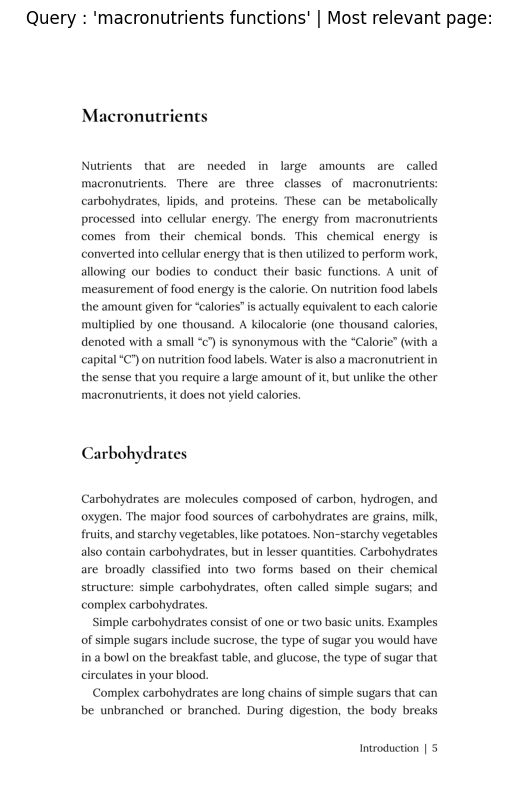

In [119]:
import fitz

#Open pdf and load the target
pdf_path="human-nutrition-text.pdf" #requires a pdf to be download
doc=fitz.open(pdf_path)
page=doc.load_page(5+41) # +41 cause textbook starts from 41 page

#get the image of page
img=page.get_pixmap(dpi=300)

#Optinal save the image
#img.save("output_filname.png")
doc.close()

#convert the Pixmap into numpy array
img_array=np.frombuffer(img.samples_mv,
                        dtype=np.uint8).reshape((img.h, img.w, img.n))

#display the image using matplotlib
import matplotlib.pyplot as plt
plt.figure(figsize=(13, 10))
plt.imshow(img_array)
plt.title(f"Query : '{query}' | Most relevant page:")
plt.axis('off') #Turn of axis
plt.show()

Nice!

Now we can do extra research if we'd like.

We could repeat this workflow for any kind of query we'd like on our textbook.

And it would also work for other datatypes too.

We could use semantic search on customer support documents.

Or email threads.

Or company plans.

Or our old journal entries.

Almost anything!

The workflow is the same:

`ingest documents -> split into chunks -> embed chunks -> make a query -> embed the query -> compare query embedding to chunk embeddings`

And we get relevant resources *along with* the source they came from!

That's the **retrieval** part of Retrieval Augmented Generation (RAG).

Before we get to the next two steps, let's take a small aside and discuss similarity measures.

### Similarity measures: dot product and cosine similarity

Let's talk similarity measures between vectors.

Specifically, embedding vectors which are representations of data with magnitude and direction in high dimensional space (our embedding vectors have 768 dimensions).

Two of the most common you'll across are the dot product and cosine similarity.

They are quite similar.

The main difference is that cosine similarity has a normalization step.

| Similarity measure | Description | Code |
| ----- | ----- | ----- |
| [Dot Product](https://en.wikipedia.org/wiki/Dot_product) | - Measure of magnitude and direction between two vectors<br>- Vectors that are aligned in direction and magnitude have a higher positive value<br>- Vectors that are opposite in direction and magnitude have a higher negative value | [`torch.dot`](https://pytorch.org/docs/stable/generated/torch.dot.html), [`np.dot`](https://numpy.org/doc/stable/reference/generated/numpy.dot.html), [`sentence_transformers.util.dot_score`](https://www.sbert.net/docs/package_reference/util.html#sentence_transformers.util.dot_score) |
| [Cosine Similarity](https://en.wikipedia.org/wiki/Cosine_similarity) | - Vectors get normalized by magnitude/[Euclidean norm](https://en.wikipedia.org/wiki/Norm_(mathematics))/L2 norm so they have unit length and are compared more so on direction<br>- Vectors that are aligned in direction have a value close to 1<br>- Vectors that are opposite in direction have a value close to -1 | [`torch.nn.functional.cosine_similarity`](https://pytorch.org/docs/stable/generated/torch.nn.functional.cosine_similarity.html), [`1 - scipy.spatial.distance.cosine`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.cosine.html) (subtract the distance from 1 for similarity measure), [`sentence_transformers.util.cos_sim`](https://www.sbert.net/docs/package_reference/util.html#sentence_transformers.util.cos_sim) |

For text similarity, you generally want to use cosine similarity as you are after the semantic measurements (direction) rather than magnitude.

In our case, our embedding model `all-mpnet-base-v2` outputs normalized outputs (see the [Hugging Face model card](https://huggingface.co/sentence-transformers/all-mpnet-base-v2#usage-huggingface-transformers) for more on this) so dot product and cosine similarity return the same results. However, dot product is faster due to not need to perform a normalize step.

To make things bit more concrete, let's make simple dot product and cosine similarity functions and view their results on different vectors.

> **Note:** Similarity measures between vectors and embeddings can be used on any kind of embeddings, not just text embeddings. For example, you could measure image embedding similarity or audio embedding similarity. Or with text and image models like [CLIP](https://github.com/mlfoundations/open_clip), you can measure the similarity between text and image embeddings.

In [120]:
import torch

def dot_product(vector1, vector2):
  return torch.dot(vector1, vector2)

def cosine_similarity(vector1, vector2):
  dot_product=torch.dot(vector1, vector2)

  #Get Euclidean/L2 norm of each vector (it removes the magnitude and keeps the direction)
  norm_vector1= torch.sqrt(torch.sum(vector1**2))
  norm_vector2= torch.sqrt(torch.sum(vector2**2))

  return dot_product/ (norm_vector1 * norm_vector2)

#Example tensors
vector1= torch.tensor([1, 2, 3], dtype=torch.float32)
vector2=torch.tensor([1, 2, 3], dtype=torch.float32)
vector3=torch.tensor([4, 5, 6], dtype=torch.float32)
vector4=torch.tensor([-1, -2, -3], dtype=torch.float32)

#Lets calculate the dot product
print(" Dot product between vector 1 and vector 2 :", dot_product(vector1, vector2))
print("Dot product between vector 1 and vector 3 :", dot_product(vector1, vector3))
print("Dot Product between vector 1 and vector 4 :", dot_product(vector1, vector4))

#Calculate Cosin similarity
print(" Cosine Similarity between vector 1 and vector 2 :", cosine_similarity(vector1, vector2))
print("Cosine Similarity between vector 1 and vector 3 :", cosine_similarity(vector1, vector3))
print("Cosine Similarity between vector 1 and vector 4 :", cosine_similarity(vector1, vector4))

 Dot product between vector 1 and vector 2 : tensor(14.)
Dot product between vector 1 and vector 3 : tensor(32.)
Dot Product between vector 1 and vector 4 : tensor(-14.)
 Cosine Similarity between vector 1 and vector 2 : tensor(1.0000)
Cosine Similarity between vector 1 and vector 3 : tensor(0.9746)
Cosine Similarity between vector 1 and vector 4 : tensor(-1.0000)


Notice for both dot product and cosine similarity the comparisons of `vector1` and `vector2` are the opposite of `vector1` and `vector4`.

Comparing `vector1` and `vector2` both equations return positive values (14 for dot product and 1.0 for cosine similarity).

But comparing `vector1` and `vector4` the result is in the negative direction.

This makes sense because `vector4` is the negative version of `vector1`.

Whereas comparing `vector1` and `vector3` shows a different outcome.

For the dot product, the value is positive and larger then the comparison of two exactly the same vectors (32 vs 14).

However, for the cosine similarity, thanks to the normalization step, comparing `vector1` and `vector3` results in a postive value close to 1 but not exactly 1.

It is because of this that when comparing text embeddings, cosine similarity is generally favoured as it measures the difference in direction of a pair of vectors rather than difference in magnitude.

And it is this difference in direction that is more generally considered to capture the semantic meaning/vibe of the text.

The good news is that as mentioned before, the outputs of our embedding model `all-mpnet-base-v2` are already normalized.

So we can continue using the dot product (cosine similarity is dot product + normalization).

With similarity measures explained, let's functionize our semantic search steps from above so we can repeat them.

### Functionizing our semantic search pipeline

Let's put all of the steps from above for semantic search into a function or two so we can repeat the workflow.

In [121]:

def retrieve_relevant_resources(query: str,
                                embeddings: torch.Tensor,
                                model: SentenceTransformer = embedding_model,
                                n_resources_to_return: int = 5,
                                print_time: bool = True):
    """
    Embeds a query with model and returns top k scores and indices
    for embeddings.
    """

    # Embed the query
    query_embedding = model.encode(
        query,
        convert_to_tensor=True
    )

    # Ensure both tensors are on the same device
    query_embedding = query_embedding.to(embeddings.device)

    # Get dot product scores on embeddings
    start_timer = timer()
    dot_scores = util.dot_score(query_embedding, embeddings)[0]
    end_time = timer()

    if print_time:
        print(
            f"[INFO] Time taken to get scores on {len(embeddings)} "
            f"embeddings: {end_time - start_timer:.5f} seconds."
        )

    scores, indices = torch.topk(
        input=dot_scores,
        k=n_resources_to_return
    )

    return scores, indices



def print_top_results_and_scores(
    query: str,
    embeddings: torch.Tensor,
    pages_and_chunks: list[dict] = pages_and_chunks,
    n_resources_to_return: int = 5
):
    """
    Retrieves the most relevant resources and prints their scores.
    """

    scores, indices = retrieve_relevant_resources(
        query=query,
        embeddings=embeddings,
        n_resources_to_return=n_resources_to_return
    )

    print(f"Query: {query}\n")
    print("Results:")

    for score, idx in zip(scores, indices):
        print(f"Score: {score:.4f}")

        print_wrapped(pages_and_chunks[idx]["sentence_chunk"])

        print(f"Page number: {pages_and_chunks[idx]['page_number']}")
        print("\n")

Excellent! Now let's test our functions out.

In [122]:
query = "symptoms of pellagra"

# Get just the scores and indices of top related results
scores, indices = retrieve_relevant_resources(query=query,
                                              embeddings=embeddings)
scores, indices

[INFO] Time taken to get scores on 1680 embeddings: 0.00009 seconds.


(tensor([0.5000, 0.3741, 0.2959, 0.2793, 0.2721], device='cuda:0'),
 tensor([ 822,  853, 1536, 1555, 1531], device='cuda:0'))

In [123]:
print_top_results_and_scores(query=query,
                             embeddings=embeddings)

[INFO] Time taken to get scores on 1680 embeddings: 0.00009 seconds.
Query: symptoms of pellagra

Results:
Score: 0.5000
Niacin deficiency is commonly known as pellagra and the symptoms include
fatigue, decreased appetite, and indigestion.  These symptoms are then commonly
followed by the four D’s: diarrhea, dermatitis, dementia, and sometimes death.
Figure 9.12  Conversion of Tryptophan to Niacin Water-Soluble Vitamins | 565
Page number: 565


Score: 0.3741
car. Does it drive faster with a half-tank of gas or a full one?It does not
matter; the car drives just as fast as long as it has gas. Similarly, depletion
of B vitamins will cause problems in energy metabolism, but having more than is
required to run metabolism does not speed it up. Buyers of B-vitamin supplements
beware; B vitamins are not stored in the body and all excess will be flushed
down the toilet along with the extra money spent. B vitamins are naturally
present in numerous foods, and many other foods are enriched with th

### Semantic search/vector search extensions

We've covered an exmaple of using embedding vector search to find relevant results based on a query.

However, you could also add to this pipeline with traditional keyword search.

Many modern search systems use keyword and vector search in tandem.

Our dataset is small and allows for an exhaustive search (comparing the query to *every* possible result) but if you start to work with large scale datasets with hundred of thousands, millions or even billions of vectors, you'll want to implement an index.

You can think of an index as sorting your embeddings before you search through them.

So it narrows down the search space.

For example, it would be inefficient to search every word in the dictionary to find the word "duck", instead you'd go straight to the letter D, perhaps even straight to the back half of the letter D, find words close to "duck" before finding it.

That's how an index can help search through many examples without comprimising too much on speed or quality (for more on this, check out [nearest neighbour search](https://en.wikipedia.org/wiki/Nearest_neighbor_search)).

One of the most popular indexing libraries is [Faiss](https://github.com/facebookresearch/faiss).

Faiss is open-source and was originally created by Facebook to deal with internet-scale vectors and implements many algorithms such as [HNSW](https://arxiv.org/abs/1603.09320) (Hierarchical Naviganle Small Worlds).

### Getting an LLM for local generation

We're got our retrieval pipeline ready, let's now get the generation side of things happening.

To perform generation, we're going to use a Large Language Model (LLM).

LLMs are designed to generate an output given an input.

In our case, we want our LLM to generate and output of text given a input of text.

And more specifically, we want the output of text to be generated based on the context of relevant information to the query.

The input to an LLM is often referred to as a prompt.

We'll augment our prompt with a query as well as context from our textbook related to that query.

> **Which LLM should I use?**

There are many LLMs available.

Two of the main questions to ask from this is:
1. Do I want it to run locally?
2. If yes, how much compute power can I dedicate?

If you're after the absolute best performance, you'll likely want to use an API (not running locally) such as GPT-4 or Claude 3. However, this comes with the tradeoff of sending your data away and then awaiting a response.

For our case, since we want to set up a local pipeline and run it on our own GPU, we'd answer "yes" to the first question and then the second question will depend on what hardware we have available.

To find open-source LLMs, one great resource is the [Hugging Face open LLM leaderboard](https://huggingface.co/spaces/HuggingFaceH4/open_llm_leaderboard).

The leaderboard compares many of the latest and greatest LLMs on various benchmarks.

Another great resource is [TheBloke on Hugging Face](https://huggingface.co/TheBloke), an account which provides an extensive range of quantized (models that have been made smaller) LLMs.

A rule of thumb for LLMs (and deep learning models in general) is that the higher the number of parameters, the better the model performs.

It may be tempting to go for the largest size model (e.g. a 70B parameter model rather than a 7B parameter model) but a larger size model may not be able to run on your available hardware.

The following table gives an insight into how much GPU memory you'll need to load an LLM with different sizes and different levels of [numerical precision](https://en.wikipedia.org/wiki/Precision_(computer_science)).

They are based on the fact that 1 float32 value (e.g. `0.69420`) requires 4 bytes of memory and 1GB is approximately 1,000,000,000 (one billion) bytes.

| Model Size (Billion Parameters) | Float32 VRAM (GB) | Float16 VRAM (GB) | 8-bit VRAM (GB) | 4-bit VRAM (GB) |
|-----|-----|-----|-----|-----|
| 1B                              | ~4                | ~2                | ~1              | ~0.5            |
| 7B (e.g., [Llama 2 7B](https://huggingface.co/meta-llama/Llama-2-7b), [Gemma 7B](https://huggingface.co/google/gemma-7b-it), [Mistral 7B](https://huggingface.co/mistralai/Mistral-7B-v0.1))             | ~28               | ~14               | ~7              | ~3.5            |
| 10B                             | ~40               | ~20               | ~10             | ~5              |
| 70B (e.g, Llama 2 70B)          | ~280              | ~140              | ~70             | ~35             |
| 100B                            | ~400              | ~200              | ~100            | ~50             |
| 175B                            | ~700              | ~350              | ~175            | ~87.5           |

<br>

> **Note:** Loading a model in a lower precision (e.g. 8-bit instead of float16) generally lowers performance. Lower precision can help to reduce computing requirements, however sometimes the performance degradation in terms of model output can be substantial. Finding the right speed/performance tradeoff will often require many experiments.

### Checking local GPU memory availability

Let's find out what hardware we've got available and see what kind of model(s) we'll be able to load.

> **Note:** You can also check this with the `!nvidia-smi` command.

In [124]:
import torch

gpu_memory_bytes=torch.cuda.get_device_properties(0).total_memory
gpu_memory_gb=round(gpu_memory_bytes/ (2**30))
print(f"Available GPU memory {gpu_memory_gb} GB")

Available GPU memory 15 GB


Ok wonderful!

I'm running this notebook on Google Colab with a NVIDIA T4, so I've got 15GB of VRAM available.

However, this may be different on your end.

Looking at the table above, it seems we can run a ~7-10B parameter model in float16 precision pretty comfortably.

But we could also run a smaller one if we'd like.

Let's try out the recently released (at the time March 2024, and currently i am writing this on October 2026) LLM from Google, [Gemma](https://huggingface.co/blog/gemma).

Specifically, we'll use the `gemma-7b-it` version which stands for Gemma 7B Instruction-Tuned.

Instruction tuning is the process of tuning a raw language model to follow instructions.

These are the kind of models you'll find in most chat-based assistants such as ChatGPT, Gemini or Claude.

The following table shows different amounts of GPU memory requirements for different verions of the Gemma LLMs with varying levels of precision.

| Model             | Precision | Min-Memory (Bytes) | Min-Memory (MB) | Min-Memory (GB) | Recommended Memory (GB) | Hugging Face ID |
|-------------------|-----------|----------------|-------------|-------------| ----- | ----- |
| [Gemma 2B](https://huggingface.co/google/gemma-2b-it)          | 4-bit     | 2,106,749,952  | 2009.15     | 1.96        | ~5.0 | [`gemma-2b`](https://huggingface.co/google/gemma-2b) or [`gemma-2b-it`](https://huggingface.co/google/gemma-2b-it) for instruction tuned version |
| Gemma 2B          | Float16   | 5,079,453,696  | 4844.14     | 4.73        | ~8.0 | Same as above |
| [Gemma 7B](https://huggingface.co/google/gemma-7b-it)          | 4-bit     | 5,515,859,968  | 5260.33     | 5.14        | ~8.0 | [`gemma-7b`](https://huggingface.co/google/gemma-7b) or [`gemma-7b-it`](https://huggingface.co/google/gemma-7b-it) for instruction tuned version |
| Gemma 7B          | Float16   | 17,142,470,656 | 16348.33    | 15.97       | ~19 | Same as above |

> **Note:** `gemma-7b-it` means "instruction tuned", as in, a base LLM (`gemma-7b`) has been fine-tuned to follow instructions, similar to [`Mistral-7B-v0.1`](https://huggingface.co/mistralai/Mistral-7B-v0.1) and [`Mistral-7B-Instruct-v0.1`](https://huggingface.co/mistralai/Mistral-7B-Instruct-v0.1).
>
> There are also further quantized and smaller variants of Gemma (and other LLMs) available in various formats such as GGUF. You can see many of these on [TheBloke account on Hugging Face](https://huggingface.co/TheBloke).
>
> The version of LLM you choose to use will be largely based on project requirements and experimentation.

Based on the table above, let's write a simple if/else statement which recommends which Gemma variant we should look into using.

In [125]:
# Note: the following is Gemma focused, however, there are more and more LLMs of the 2B and 7B size appearing for local use.
if gpu_memory_gb < 5.1:
    print(f"Your available GPU memory is {gpu_memory_gb}GB, you may not have enough memory to run a Gemma LLM locally without quantization.")
elif gpu_memory_gb < 8.1:
    print(f"GPU memory: {gpu_memory_gb} | Recommended model: Gemma 2B in 4-bit precision.")
    use_quantization_config = True
    model_id = "google/gemma-2b-it"
elif gpu_memory_gb < 19.0:
    print(f"GPU memory: {gpu_memory_gb} | Recommended model: Gemma 2B in float16 or Gemma 7B in 4-bit precision.")
    use_quantization_config = False
    model_id = "google/gemma-2b-it"
elif gpu_memory_gb > 19.0:
    print(f"GPU memory: {gpu_memory_gb} | Recommend model: Gemma 7B in 4-bit or float16 precision.")
    use_quantization_config = False
    model_id = "google/gemma-7b-it"

print(f"use_quantization_config set to: {use_quantization_config}")
print(f"model_id set to: {model_id}")

GPU memory: 15 | Recommended model: Gemma 2B in float16 or Gemma 7B in 4-bit precision.
use_quantization_config set to: False
model_id set to: google/gemma-2b-it


In [126]:
#Lets logging to hugging face(u have to add the HF token in the Secret tab if u are in colab and name as "HuggingFaceToken")
from google.colab import userdata
from huggingface_hub import login

login(token=userdata.get("HuggingFaceToken"))

In [128]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import is_flash_attn_2_available

# 1. Create quantization config for smaller model loading (optional)
# Requires !pip install bitsandbytes accelerate, see: https://github.com/TimDettmers/bitsandbytes, https://huggingface.co/docs/accelerate/
# For models that require 4-bit quantization (use this if you have low GPU memory available)
from transformers import BitsAndBytesConfig
quantization_config = BitsAndBytesConfig(load_in_4bit=True,
                                         bnb_4bit_compute_dtype=torch.float16)

# Bonus: Setup Flash Attention 2 for faster inference, default to "sdpa" or "scaled dot product attention" if it's not available
# Flash Attention 2 requires NVIDIA GPU compute capability of 8.0 or above, see: https://developer.nvidia.com/cuda-gpus
# Requires !pip install flash-attn, see: https://github.com/Dao-AILab/flash-attention
if (is_flash_attn_2_available()) and (torch.cuda.get_device_capability(0)[0] >= 8):
  attn_implementation = "flash_attention_2"
else:
  attn_implementation = "sdpa"
print(f"[INFO] Using attention implementation: {attn_implementation}")

# 2. Pick a model we'd like to use (this will depend on how much GPU memory you have available)
#model_id = "google/gemma-2b-it"
model_id = model_id # (we already set this above)
print(f"[INFO] Using model_id: {model_id}")

# 3. Instantiate tokenizer (tokenizer turns text into numbers ready for the model)
tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name_or_path=model_id)

# 4. Instantiate the model
llm_model = AutoModelForCausalLM.from_pretrained(pretrained_model_name_or_path=model_id,
                                                 torch_dtype=torch.float16, # datatype to use, we want float16
                                                 quantization_config=quantization_config if use_quantization_config else None,
                                                 low_cpu_mem_usage=False, # use full memory
                                                 attn_implementation=attn_implementation) # which attention version to use

if not use_quantization_config: # quantization takes care of device setting automatically, so if it's not used, send model to GPU
    llm_model.to("cuda")

[INFO] Using attention implementation: sdpa
[INFO] Using model_id: google/gemma-2b-it


Loading weights:   0%|          | 0/164 [00:00<?, ?it/s]

Oops i ran the cell twice (no problem still it is fine) but u need to run  it once .

Anyhow we got an LLM.
Let's check it out.

In [129]:
llm_model

GemmaForCausalLM(
  (model): GemmaModel(
    (embed_tokens): GemmaTextScaledWordEmbedding(256000, 2048, padding_idx=0)
    (layers): ModuleList(
      (0-17): 18 x GemmaDecoderLayer(
        (self_attn): GemmaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=256, bias=False)
          (v_proj): Linear(in_features=2048, out_features=256, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): GemmaMLP(
          (gate_proj): Linear(in_features=2048, out_features=16384, bias=False)
          (up_proj): Linear(in_features=2048, out_features=16384, bias=False)
          (down_proj): Linear(in_features=16384, out_features=2048, bias=False)
          (act_fn): GELUTanh()
        )
        (input_layernorm): GemmaRMSNorm((2048,), eps=1e-06)
        (post_attention_layernorm): GemmaRMSNorm((2048,), eps=1e-06)
      )
    )
    (norm): GemmaRMSN

Ok, ok a bunch of layers ranging from embedding layers to attention layers (see the `GemmaFlashAttention2` layers!) to MLP and normalization layers.

The good news is that we don't have to know too much about these to use the model.

How about we get the number of parameters in our model?

In [131]:
def get_model_num_params(model: torch.nn.Module):
  return sum([param.numel() for param in model.parameters()])
get_model_num_params(llm_model)

2506172416

Hmm, turns out that Gemma 2B is really Gemma 2.5B.

It pays to do your own investigations!

How about we get the models memory requirements?

In [132]:
def get_model_mem_size(model: torch.nn.Module):
    """
    Get how much memory a PyTorch model takes up.

    See: https://discuss.pytorch.org/t/gpu-memory-that-model-uses/56822
    """
    # Get model parameters and buffer sizes
    mem_params = sum([param.nelement() * param.element_size() for param in model.parameters()])
    mem_buffers = sum([buf.nelement() * buf.element_size() for buf in model.buffers()])

    # Calculate various model sizes
    model_mem_bytes = mem_params + mem_buffers # in bytes
    model_mem_mb = model_mem_bytes / (1024**2) # in megabytes
    model_mem_gb = model_mem_bytes / (1024**3) # in gigabytes

    return {"model_mem_bytes": model_mem_bytes,
            "model_mem_mb": round(model_mem_mb, 2),
            "model_mem_gb": round(model_mem_gb, 2)}

get_model_mem_size(llm_model)

{'model_mem_bytes': 5012345858, 'model_mem_mb': 4780.15, 'model_mem_gb': 4.67}

Nice, looks like this model takes up 4.67GB of space on the GPU.

Plus a little more for the forward pass (due to all the calculations happening between the layers).

Hence why I rounded it up to be ~5GB in the table above.

Now let's get to the fun part, generating some text!

### Generating text with our LLM

We can generate text with our LLM `model` instance by calling the [`generate()` method](https://huggingface.co/docs/transformers/v4.38.2/en/main_classes/text_generation#transformers.GenerationConfig) (this method has plenty of options to pass into it alongside the text) on it and passing it a tokenized input.

The tokenized input comes from passing a string of text to our `tokenizer`.

It's important to note that you should use a tokenizer that has been paired with a model.

Otherwise if you try to use a different tokenizer and then pass those inputs to a model, you will likely get errors/strange results.

For some LLMs, there's a specific template you should pass to them for ideal outputs.

For example, the `gemma-2b-it` model has been trained in a dialogue fashion (instruction tuning).

In this case, our `tokenizer` has a [`apply_chat_template()` method](https://huggingface.co/docs/transformers/main/en/internal/tokenization_utils#transformers.PreTrainedTokenizerBase.apply_chat_template) which can prepare our input text in the right format for the model.

Let's try it out.

> **Note:** The following demo has been modified from the Hugging Face model card for [Gemma 2B](https://huggingface.co/google/gemma-2b-it). Many similar demos of usage are available on the model cards of similar models.

In [135]:
input_text="what are macronurtients, and what roles do they play in the human body?"
print(f"Input text :\n{input_text}")

#create a prompt template for instruction-tuned model
dialogue_template= [
    {
        "role": "user",
        "content": input_text
    }
]

#Apply the chat template
prompt=tokenizer.apply_chat_template(conversation=dialogue_template,
                                     tokenize=False, #keep as raw text (not tokenzied)
                                     add_generation_prompt=True)

print(f"\nPrompt (formatted):\n{prompt}")

Input text :
what are macronurtients, and what roles do they play in the human body?

Prompt (formatted):
<bos><start_of_turn>user
what are macronurtients, and what roles do they play in the human body?<end_of_turn>
<start_of_turn>model



Notice the scaffolding around our input text, this is the kind of turn-by-turn instruction tuning our model has gone through.

Our next step is to tokenize this formatted text and pass it to our model's `generate()` method.

We'll make sure our tokenized text is on the same device as our model (GPU) using `to("cuda")`.

Let's generate some text!

We'll time it for fun with the `%%time` magic.

In [136]:
%%time

# Tokenize the input text (turn it into numbers) and send it to GPU
input_ids = tokenizer(prompt, return_tensors="pt").to("cuda")
print(f"Model input (tokenized):\n{input_ids}\n")

# Generate outputs passed on the tokenized input
# See generate docs: https://huggingface.co/docs/transformers/v4.38.2/en/main_classes/text_generation#transformers.GenerationConfig
outputs = llm_model.generate(**input_ids,
                             max_new_tokens=256) # define the maximum number of new tokens to create
print(f"Model output (tokens):\n{outputs[0]}\n")

Model input (tokenized):
{'input_ids': tensor([[     2,      2,    106,   1645,    108,   5049,    708, 186809, 177880,
            990, 235269,    578,   1212,  16065,    749,    984,   1554,    575,
            573,   3515,   2971, 235336,    107,    108,    106,   2516,    108]],
       device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1]], device='cuda:0')}

Model output (tokens):
tensor([     2,      2,    106,   1645,    108,   5049,    708, 186809, 177880,
           990, 235269,    578,   1212,  16065,    749,    984,   1554,    575,
           573,   3515,   2971, 235336,    107,    108,    106,   2516,    108,
         21404, 235269,   1517, 235303, 235256,    476,  11352,  15844,    576,
        186809, 184592,    578,   1024,  16065,    575,    573,   3515,   2971,
        235292,    109,    688,  12298,   1695, 184592,    688,    708,  37132,
           674,    573,   2971,   4026,    575,   

Woohoo! We just generated some text on our local GPU!

Well not just yet...

Our LLM accepts tokens in and sends tokens back out.

We can convert the output tokens to text using [`tokenizer.decode()`](https://huggingface.co/docs/transformers/main_classes/tokenizer#transformers.PreTrainedTokenizer.decode).

In [138]:
#Decode output tokens to text
outputs_decoded=tokenizer.decode(outputs[0])
print(f"Model output (decoded):\n{outputs_decoded}\n")

Model output (decoded):
<bos><bos><start_of_turn>user
what are macronurtients, and what roles do they play in the human body?<end_of_turn>
<start_of_turn>model
Sure, here's a detailed explanation of macronutrients and their roles in the human body:

**Macronutrients** are nutrients that the body needs in large amounts to maintain good health. They are divided into two main categories: macronutrients and micronutrients.

**Macronutrients** include:

* **Carbohydrates:** Provide energy for the body's cells and tissues. They are the body's main source of fuel.
* **Protein:** Builds and repairs tissues, produces enzymes, and helps the body fight infection.
* **Fat:** Insulates the body, helps absorb vitamins, and provides energy.

**Micronutrients** include:

* **Vitamins:** Are organic substances that the body cannot produce on its own and must be obtained from food. They are essential for many bodily functions, including metabolism, cell growth, and immune function.
* **Minerals:** Are i

Woah! That looks like a pretty good answer.

But notice how the output contains the prompt text as well?

How about we do a little formatting to replace the prompt in the output text?

> **Note:** `"<bos>"` and `"<eos>"` are special tokens to denote "beginning of sentence" and "end of sentence" respectively.

In [139]:
print(f"Input text: {input_text}\n")
print(f"Output text:\n{outputs_decoded.replace(prompt, '').replace('<bos>', '').replace('<eos>', '')}")

Input text: what are macronurtients, and what roles do they play in the human body?

Output text:
Sure, here's a detailed explanation of macronutrients and their roles in the human body:

**Macronutrients** are nutrients that the body needs in large amounts to maintain good health. They are divided into two main categories: macronutrients and micronutrients.

**Macronutrients** include:

* **Carbohydrates:** Provide energy for the body's cells and tissues. They are the body's main source of fuel.
* **Protein:** Builds and repairs tissues, produces enzymes, and helps the body fight infection.
* **Fat:** Insulates the body, helps absorb vitamins, and provides energy.

**Micronutrients** include:

* **Vitamins:** Are organic substances that the body cannot produce on its own and must be obtained from food. They are essential for many bodily functions, including metabolism, cell growth, and immune function.
* **Minerals:** Are inorganic substances that the body needs in smaller amounts tha

How cool is that!

We just officially generated text from an LLM running locally.

So we've covered the R (retrieval) and G (generation) of RAG.

How about we check out the last step?

Augmentation.

First, let's put together a list of queries we can try out with our pipeline.

In [140]:
# Nutrition-style questions generated with GPT4
gpt4_questions = [
    "What are the macronutrients, and what roles do they play in the human body?",
    "How do vitamins and minerals differ in their roles and importance for health?",
    "Describe the process of digestion and absorption of nutrients in the human body.",
    "What role does fibre play in digestion? Name five fibre containing foods.",
    "Explain the concept of energy balance and its importance in weight management."
]

# Manually created question list
manual_questions = [
    "How often should infants be breastfed?",
    "What are symptoms of pellagra?",
    "How does saliva help with digestion?",
    "What is the RDI for protein per day?",
    "water soluble vitamins"
]

query_list = gpt4_questions + manual_questions

And now let's check if our `retrieve_relevant_resources()` function works with our list of queries.

In [141]:
import random
query=random.choice(query_list)

print(f"Query: {query}")

#Gets just scores and indices of top related results
scores, indices = retrieve_relevant_resources(query=query,
                                              embeddings=embeddings)

scores, indices

Query: How does saliva help with digestion?
[INFO] Time taken to get scores on 1680 embeddings: 0.00267 seconds.


(tensor([0.6383, 0.6099, 0.5877, 0.5853, 0.5845], device='cuda:0'),
 tensor([364, 139, 365, 134, 366], device='cuda:0'))

Beautiful!
Lets Augument now!

### Augmenting our prompt with context items

What we'd like to do with augmentation is take the results from our search for relevant resources and put them into the prompt that we pass to our LLM.

In essence, we start with a base prompt and update it with context text.

Let's write a function called `prompt_formatter` that takes in a query and our list of context items (in our case it'll be select indices from our list of dictionaries inside `pages_and_chunks`) and then formats the query with text from the context items.

We'll apply the dialogue and chat template to our prompt before returning it as well.

> **Note:** The process of augmenting or changing a prompt to an LLM is known as prompt engineering. And the best way to do it is an active area of research. For a comprehensive guide on different prompt engineering techniques, I'd recommend the Prompt Engineering Guide ([promptingguide.ai](https://www.promptingguide.ai/)), [Brex's Prompt Engineering Guide](https://github.com/brexhq/prompt-engineering) and the paper [Prompt Design and Engineering: Introduction and Advanced Models](https://arxiv.org/abs/2401.14423).

In [142]:
def prompt_formatter(query: str,
                     context_items: list[dict]) -> str:
    """
    Augments query with text-based context from context_items.
    """
    # Join context items into one dotted paragraph
    context = "- " + "\n- ".join([item["sentence_chunk"] for item in context_items])

    # Create a base prompt with examples to help the model
    # Note: this is very customizable, I've chosen to use 3 examples of the answer style we'd like.
    # We could also write this in a txt file and import it in if we wanted.
    base_prompt = """Based on the following context items, please answer the query.
Give yourself room to think by extracting relevant passages from the context before answering the query.
Don't return the thinking, only return the answer.
Make sure your answers are as explanatory as possible.
Use the following examples as reference for the ideal answer style.
\nExample 1:
Query: What are the fat-soluble vitamins?
Answer: The fat-soluble vitamins include Vitamin A, Vitamin D, Vitamin E, and Vitamin K. These vitamins are absorbed along with fats in the diet and can be stored in the body's fatty tissue and liver for later use. Vitamin A is important for vision, immune function, and skin health. Vitamin D plays a critical role in calcium absorption and bone health. Vitamin E acts as an antioxidant, protecting cells from damage. Vitamin K is essential for blood clotting and bone metabolism.
\nExample 2:
Query: What are the causes of type 2 diabetes?
Answer: Type 2 diabetes is often associated with overnutrition, particularly the overconsumption of calories leading to obesity. Factors include a diet high in refined sugars and saturated fats, which can lead to insulin resistance, a condition where the body's cells do not respond effectively to insulin. Over time, the pancreas cannot produce enough insulin to manage blood sugar levels, resulting in type 2 diabetes. Additionally, excessive caloric intake without sufficient physical activity exacerbates the risk by promoting weight gain and fat accumulation, particularly around the abdomen, further contributing to insulin resistance.
\nExample 3:
Query: What is the importance of hydration for physical performance?
Answer: Hydration is crucial for physical performance because water plays key roles in maintaining blood volume, regulating body temperature, and ensuring the transport of nutrients and oxygen to cells. Adequate hydration is essential for optimal muscle function, endurance, and recovery. Dehydration can lead to decreased performance, fatigue, and increased risk of heat-related illnesses, such as heat stroke. Drinking sufficient water before, during, and after exercise helps ensure peak physical performance and recovery.
\nNow use the following context items to answer the user query:
{context}
\nRelevant passages: <extract relevant passages from the context here>
User query: {query}
Answer:"""

    # Update base prompt with context items and query
    base_prompt = base_prompt.format(context=context, query=query)

    # Create prompt template for instruction-tuned model
    dialogue_template = [
        {"role": "user",
        "content": base_prompt}
    ]

    # Apply the chat template
    prompt = tokenizer.apply_chat_template(conversation=dialogue_template,
                                          tokenize=False,
                                          add_generation_prompt=True)
    return prompt

Hmm Looks good lets try our function out.

In [146]:
query = random.choice(query_list)
print(f"Query: {query}")

#get relevant resources
scores, indices = retrieve_relevant_resources(query=query,
                                              embeddings=embeddings)

#Create a list of context items
context_items = [pages_and_chunks[i] for i in indices]

#Format prompt with context items
prompt = prompt_formatter(query=query,
                          context_items=context_items)
print(prompt)

Query: What is the RDI for protein per day?
[INFO] Time taken to get scores on 1680 embeddings: 0.00012 seconds.
<bos><start_of_turn>user
Based on the following context items, please answer the query.
Give yourself room to think by extracting relevant passages from the context before answering the query.
Don't return the thinking, only return the answer.
Make sure your answers are as explanatory as possible.
Use the following examples as reference for the ideal answer style.

Example 1:
Query: What are the fat-soluble vitamins?
Answer: The fat-soluble vitamins include Vitamin A, Vitamin D, Vitamin E, and Vitamin K. These vitamins are absorbed along with fats in the diet and can be stored in the body's fatty tissue and liver for later use. Vitamin A is important for vision, immune function, and skin health. Vitamin D plays a critical role in calcium absorption and bone health. Vitamin E acts as an antioxidant, protecting cells from damage. Vitamin K is essential for blood clotting and b

What a good looking prompt it is!

We can tokenize this and pass it straight to our LLM.

In [147]:
%%time

input_ids = tokenizer(prompt, return_tensors="pt").to("cuda")

#generate an output of tokens
outputs = llm_model.generate(**input_ids,
                             temperature=0.7, #lower temperature= more deterministic outputs, higher temperature = more creative outputs
                             do_sample=True, # whether or not to use sampling, see https://huyenchip.com/2024/01/16/sampling.html for more
                             max_new_tokens=256) # how many new tokens to generate from prompt

# Turn the output tokens into text or u can say decode O/P tokens
output_text = tokenizer.decode(outputs[0])

print(f"Query: {query}")
print(f"RAG answer:\n{output_text.replace(prompt, '')}")

Query: What is the RDI for protein per day?
RAG answer:
<bos>The relevant passage from the context is:

> The RDAs for protein were determined by assessing nitrogen balance. Nitrogen is one of the four basic elements contained in all amino acids. When proteins are broken down and amino acids are catabolized, nitrogen is released.<eos>
CPU times: user 2.23 s, sys: 3 ms, total: 2.23 s
Wall time: 2.33 s


Yesssssss!!!

Our RAG pipeline is complete!

We just Retrieved, Augmented and Generated!

And all on our own local GPU!

How about we functionize the generation step to make it easier to use?

We can put a little formatting on the text being returned to make it look nice too.

And we'll make an option to return the context items if needed as well.

In [148]:
def ask(query,
        temperature=0.7,
        max_new_tokens=512,
        format_answer_text=True,
        return_answer_only=True):
    """
    Takes a query, finds relevant resources/context and generates an answer to the query based on the relevant resources.
    """

    #get just the scores and indices of top related results
    scores, indices = retrieve_relevant_resources(query=query,
                                                  embeddings=embeddings)

    #Create a list of context items
    context_items = [pages_and_chunks[i] for i in indices]

    #Add score to context item
    for i, item in enumerate(context_items):
        item["score"] = scores[i].cpu() # return score back to CPU

    #format the prompt with context items
    prompt = prompt_formatter(query=query,
                              context_items=context_items)

    #Tokenize the prompt
    input_ids = tokenizer(prompt, return_tensors="pt").to("cuda")

    #generate an output of tokens
    outputs = llm_model.generate(**input_ids,
                                 temperature=temperature,
                                 do_sample=True,
                                 max_new_tokens=max_new_tokens)

    # Turn the output tokens into text
    output_text = tokenizer.decode(outputs[0])

    if format_answer_text:
        # Replace special tokens and unnecessary help message
        output_text = output_text.replace(prompt, "").replace("<bos>", "").replace("<eos>", "").replace("Sure, here is the answer to the user query:\n\n", "")

    # Only return the answer without the context items
    if return_answer_only:
        return output_text

    return output_text, context_items

What a good looking function!

The workflow could probably be a little refined but this should work!

Let's try it out.

In [150]:
query = random.choice(query_list)
print(f"Query: {query}")

#answer query with context and return context
answer, context_items = ask(query=query,
                            temperature=0.7,
                            max_new_tokens=512,
                            return_answer_only=False)

print(f"Answer:\n")
print_wrapped(answer)
print(f"Context items:")
context_items

Query: What are symptoms of pellagra?
[INFO] Time taken to get scores on 1680 embeddings: 0.00016 seconds.
Answer:

Sure, here are the relevant passages from the context that mention symptoms of
pellagra:  > "The symptoms of pellagra include diarrhea, dermatitis, dementia,
and even death."
Context items:


[{'page_number': 565,
  'sentence_chunk': 'Niacin deficiency is commonly known as pellagra and the symptoms include fatigue, decreased appetite, and indigestion. \xa0These symptoms are then commonly followed by the four D’s: diarrhea, dermatitis, dementia, and sometimes death. Figure 9.12 \xa0Conversion of Tryptophan to Niacin Water-Soluble Vitamins | 565',
  'chunk_char_count': 308,
  'chunk_word_count': 43,
  'chunk_token_count': 77.0,
  'embedding': array([ 2.01436747e-02,  8.51660687e-03,  3.45250294e-02,  3.82414348e-02,
          6.64332435e-02,  3.54784019e-02, -4.80622128e-02,  4.61080950e-03,
          3.34787590e-04,  1.60651766e-02,  3.92620452e-02,  6.21891469e-02,
         -1.17300265e-02, -5.21841682e-02,  2.41388697e-02,  5.63627146e-02,
         -1.34784402e-02,  3.53664602e-03,  2.67130211e-02,  2.86840610e-02,
         -1.54797956e-02,  1.54494308e-02,  1.49387112e-02, -1.47909895e-02,
         -3.16866860e-02, -4.39014062e-02,  1.52432267e-02,  1.12246827e-03,
      

Local RAG workflow complete!

We've now officially got a way to Retrieve, Augment and Generate answers based on a source.

For now we can verify our answers manually by reading them and reading through the textbook.

But if you want to put this into a production system, it'd be a good idea to have some kind of evaluation on how well our pipeline works.

For example, you could use another LLM to rate the answers returned by our LLM and then use those ratings as a proxy evaluation.

However, I'll leave this and a few more interesting ideas as extensions.

## Extensions

* May want to improve text extraction with something like Marker - https://github.com/VikParuchuri/marker
* Guide to more advanced PDF extraction - https://towardsdatascience.com/extracting-text-from-pdf-files-with-python-a-comprehensive-guide-9fc4003d517
* See the following prompt engineering resources for more prompting techniques - promptinguide.ai, Brex's Prompt Engineering Guide
* What happens when a query comes through that there isn't any context in the textbook on?
* Try another embedding model (e.g. Mixed Bread AI large, `mixedbread-ai/mxbai-embed-large-v1`, see: https://huggingface.co/mixedbread-ai/mxbai-embed-large-v1)
* Try another LLM... (e.g. Mistral-Instruct)
* Try different prompts (e.g. see prompting techniques online)
* Our example only focuses on text from a PDF, however, we could extend it to include figures and images
* Evaluate the answers -> could use another LLM to rate our answers (e.g. use GPT-4 to make)
* Vector database/index for larger setup (e.g. 100,000+ chunks)
* Libraries/frameworks such as LangChain / LlamaIndex can help do many of the steps for you - so it's worth looking into those next, wanted to recreate a workflow with lower-level tools to show the principles
* Optimizations for speed
    * See Hugging Face docs for recommended speed ups on GPU - https://huggingface.co/docs/transformers/perf_infer_gpu_one
    * Optimum NVIDIA - https://huggingface.co/blog/optimum-nvidia, GitHub: https://github.com/huggingface/optimum-nvidia
    * See NVIDIA TensorRT-LLM - https://github.com/NVIDIA/TensorRT-LLM
    * See GPT-Fast for PyTorch-based optimizations - https://github.com/pytorch-labs/gpt-fast
    * Flash attention 2 (requires Ampere GPUs or newer) - https://github.com/Dao-AILab/flash-attention
* Stream text output so it looks prettier (e.g. each token appears as it gets output from the model)
* Turn the workflow into an app, see Gradio type chatbots for this - https://www.gradio.app/guides/creating-a-chatbot-fast, see local example: https://www.gradio.app/guides/creating-a-chatbot-fast#example-using-a-local-open-source-llm-with-hugging-face